# 05 · Demo


## 0 · Setup

In [1]:
!pip install -q open_clip_torch

from google.colab import drive
drive.mount('/content/drive')

import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             f1_score, confusion_matrix)

PROJECT = Path('/content/drive/MyDrive/345_term_project')
DATA, FEATS, RESULTS = PROJECT / 'data', PROJECT / 'features', PROJECT / 'results'
METRICS = ['pr_auc', 'auroc', 'f1', 'sensitivity', 'specificity', 'accuracy']
pd.set_option('display.max_colwidth', None)

Mounted at /content/drive


### Load saved files
The train/val/test splits, image embeddings from the frozen encoders, and the X-rays resized to 224×224.

In [2]:
splits = pd.read_csv(DATA / 'splits.csv')
assert json.loads((FEATS / 'image_ids.json').read_text()) == splits['image_id'].tolist(), 'feature rows out of order'

y = splits['label'].to_numpy()
TRAIN = np.flatnonzero(splits['split'] == 'train')
VAL   = np.flatnonzero(splits['split'] == 'val')
TEST  = np.flatnonzero(splits['split'] == 'test')

FEATURES = {
    'BiomedCLIP': np.load(FEATS / 'biomedclip_image.npy').astype(np.float32),
    'DINOv3':     np.hstack([np.load(FEATS / 'dinov3_cls.npy'), np.load(FEATS / 'dinov3_patchmean.npy')]).astype(np.float32),
}
IMAGES = np.load(DATA / 'images_224.npy', mmap_mode='r')

### Metrics

In [3]:
def val_threshold(y_val, p_val):
    prec, rec, thr = precision_recall_curve(y_val, p_val)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return thr[np.argmax(f1[:-1])]

def evaluate(p_val, p_test):
    t = val_threshold(y[VAL], p_val)
    yt, pred = y[TEST], (p_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    return {
        'val_pr_auc':  average_precision_score(y[VAL], p_val),
        'pr_auc':      average_precision_score(yt, p_test),
        'auroc':       roc_auc_score(yt, p_test),
        'f1':          f1_score(yt, pred, zero_division=0),
        'sensitivity': tp / (tp + fn),
        'specificity': tn / (tn + fp),
        'accuracy':    (tp + tn) / len(yt),
        'threshold':   t,
    }

def probe_probs(backbone):
    head = torch.load(RESULTS / f'probe_head_{backbone}.pt')
    logits = FEATURES[backbone] @ head['weight'].numpy().T + head['bias'].numpy()
    return 1 / (1 + np.exp(-logits[:, 0]))

## 1 · Data
RSNA Pneumonia Detection Challenge: 26,684 frontal chest X-rays. Label 1 = lung opacity (pneumonia); 0 = normal or abnormal without pneumonia ("Not normal").

Split ~70/15/15 by patient (using the RSNA→NIH patient mapping), so no person appears in two splits.

In [4]:
summary = splits.groupby('split').agg(images=('image_id', 'size'), patients=('nih_patient', 'nunique'),
                                      pneumonia_rate=('label', 'mean')).loc[['train', 'val', 'test']]
pats = {s: set(splits.loc[splits['split'] == s, 'nih_patient']) for s in summary.index}
shared = len(pats['train'] & pats['val']) + len(pats['train'] & pats['test']) + len(pats['val'] & pats['test'])
print('patients shared between splits:', shared)
print(f'PR-AUC chance level (test pneumonia rate): {y[TEST].mean():.3f}')
summary.round(3)

patients shared between splits: 0
PR-AUC chance level (test pneumonia rate): 0.224


,images,patients,pneumonia_rate
split,,,
train,18881,8168,0.227
val,3966,1650,0.217
test,3837,1634,0.224


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


### A few test X-rays

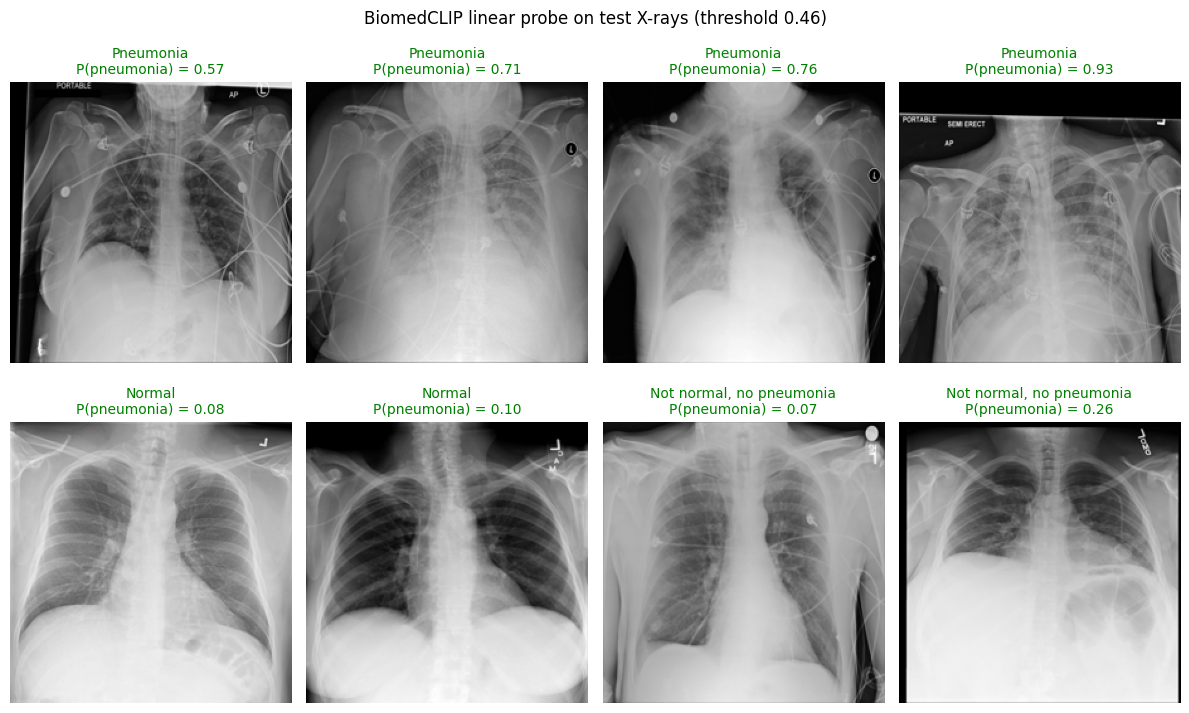

In [5]:
NAMES = {'Lung Opacity': 'Pneumonia', 'Normal': 'Normal', 'No Lung Opacity / Not Normal': 'Not normal, no pneumonia'}
p_probe = probe_probs('BiomedCLIP')
threshold = val_threshold(y[VAL], p_probe[VAL])

test = splits.iloc[TEST]
show = pd.concat([test[test['class'] == c].sample(n, random_state=0)
                  for c, n in [('Lung Opacity', 4), ('Normal', 2), ('No Lung Opacity / Not Normal', 2)]])

fig, axes = plt.subplots(2, 4, figsize=(12, 7.6))
for ax, (i, r) in zip(axes.flat, show.iterrows()):
    correct = (p_probe[i] >= threshold) == r['label']
    ax.imshow(IMAGES[i], cmap='gray')
    ax.set_title(f"{NAMES[r['class']]}\nP(pneumonia) = {p_probe[i]:.2f}", color='green' if correct else 'red', fontsize=10)
    ax.axis('off')
plt.suptitle(f'BiomedCLIP linear probe on test X-rays')
plt.tight_layout()

## 2 · Zero-shot BiomedCLIP

In [6]:
from open_clip import create_model_from_pretrained, get_tokenizer

BMC_NAME = 'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
bmc, _ = create_model_from_pretrained(BMC_NAME)
tokenizer = get_tokenizer(BMC_NAME)
bmc.eval()

PROMPTS = [
    ('a chest X-ray showing pneumonia', 'a normal chest X-ray'),
    ('chest radiograph with lung opacity consistent with pneumonia', 'chest radiograph with clear lungs'),
    ('this is a photo of pneumonia', 'this is a photo of a normal chest X-ray'),
    ('chest X-ray with pneumonia', 'chest X-ray with no findings'),
]

img = torch.tensor(FEATURES['BiomedCLIP'])
img = img / img.norm(dim=-1, keepdim=True)

rows = []
with torch.no_grad():
    for pos, neg in PROMPTS:
        txt = bmc.encode_text(tokenizer([pos, neg], context_length=256))
        txt = txt / txt.norm(dim=-1, keepdim=True)
        p = (bmc.logit_scale.exp() * img @ txt.T).softmax(-1)[:, 0].numpy()
        rows.append({'pneumonia prompt': pos, 'normal prompt': neg, **evaluate(p[VAL], p[TEST])})

zeroshot = pd.DataFrame(rows).sort_values('val_pr_auc', ascending=False).reset_index(drop=True)
zeroshot.insert(0, 'chosen', ['✓'] + [''] * (len(zeroshot) - 1))
zeroshot[['chosen', 'pneumonia prompt', 'normal prompt', 'val_pr_auc', 'pr_auc', 'auroc']].round(3)

open_clip_config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  784MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/225k [00:00<?, ?B/s]

,chosen,pneumonia prompt,normal prompt,val_pr_auc,pr_auc,auroc
0,✓,this is a photo of pneumonia,this is a photo of a normal chest X-ray,0.532,0.602,0.837
1,,a chest X-ray showing pneumonia,a normal chest X-ray,0.528,0.585,0.840
2,,chest X-ray with pneumonia,chest X-ray with no findings,0.528,0.575,0.831
3,,chest radiograph with lung opacity consistent with pneumonia,chest radiograph with clear lungs,0.456,0.508,0.811


## 3 · Linear probe

In [7]:
rows = []
for backbone in FEATURES:
    p = probe_probs(backbone)
    rows.append({'backbone': backbone, **evaluate(p[VAL], p[TEST])})
pd.DataFrame(rows).set_index('backbone')[METRICS].round(3)

,pr_auc,auroc,f1,sensitivity,specificity,accuracy
backbone,,,,,,
BiomedCLIP,0.659,0.853,0.610,0.674,0.846,0.807
DINOv3,0.637,0.838,0.591,0.651,0.841,0.799


## 4 · Full fine-tuning

In [8]:
ft = pd.concat([pd.read_csv(RESULTS / f'finetune_{b}_ft.csv') for b in ('BiomedCLIP', 'DINOv3')])
ft.set_index('backbone')[['best_epoch'] + METRICS].round(3)

,best_epoch,pr_auc,auroc,f1,sensitivity,specificity,accuracy
backbone,,,,,,,
BiomedCLIP,2,0.657,0.860,0.617,0.650,0.868,0.819
DINOv3,2,0.693,0.875,0.640,0.658,0.885,0.834


## Next steps
- LP-FT: start fine-tuning from the trained linear-probe head instead of a random head, for both BiomedCLIP and DINOv3.
- Label budgets: train the linear probe and fine-tuning on small labeled subsets (e.g. 16, 64, 256, 1,024 images and the full set) to find where fine-tuning overtakes the probe.
- Out-of-distribution test: evaluate every trained model on an outside chest X-ray dataset, used only for testing, to see which method holds up best under distribution shift.